# Weather Enrichment

In [8]:
# Set up the import
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

import matplotlib.pyplot as plt

In [ ]:
# Retrieveing the code directly from the API source

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
	"latitude": 40.7143,
	"longitude": -74.006,
	"start_date": "2026-01-01",
	"end_date": "2026-01-31",
	"hourly": ["temperature_2m", "precipitation", "rain", "snowfall", "wind_speed_10m"],
	"temperature_unit": "fahrenheit",
	"wind_speed_unit": "mph",
	"precipitation_unit": "inch",
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()
hourly_rain = hourly.Variables(2).ValuesAsNumpy()
hourly_snowfall = hourly.Variables(3).ValuesAsNumpy()
hourly_wind_speed_10m = hourly.Variables(4).ValuesAsNumpy()

hourly_data = {
	"date": pd.date_range(
		start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = hourly.Interval()),
		inclusive = "left"
	)
}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["precipitation"] = hourly_precipitation
hourly_data["rain"] = hourly_rain
hourly_data["snowfall"] = hourly_snowfall
hourly_data["wind_speed_10m"] = hourly_wind_speed_10m

hourly_dataframe = pd.DataFrame(data = hourly_data)
print("\nHourly data\n", hourly_dataframe)

Coordinates: 40.738136291503906°N -74.04254150390625°E
Elevation: 51.0 m asl
Timezone difference to GMT+0: 0s

Hourly data
                          date  temperature_2m  precipitation  rain  snowfall  \
0   2026-01-01 00:00:00+00:00       27.590000            0.0   0.0       0.0   
1   2026-01-01 01:00:00+00:00       27.590000            0.0   0.0       0.0   
2   2026-01-01 02:00:00+00:00       28.400000            0.0   0.0       0.0   
3   2026-01-01 03:00:00+00:00       29.389999            0.0   0.0       0.0   
4   2026-01-01 04:00:00+00:00       30.200001            0.0   0.0       0.0   
..                        ...             ...            ...   ...       ...   
739 2026-01-31 19:00:00+00:00       18.950001            0.0   0.0       0.0   
740 2026-01-31 20:00:00+00:00       18.410000            0.0   0.0       0.0   
741 2026-01-31 21:00:00+00:00       16.250000            0.0   0.0       0.0   
742 2026-01-31 22:00:00+00:00       12.200001            0.0   0.0       0.0

In [ ]:
# Exporting the data
hourly_dataframe.to_csv('../data/raw/nyc_weather_hourly.csv', index=False)

In [7]:
hourly_dataframe.head()

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
0,2026-01-01 00:00:00+00:00,27.590000,0.0,0.0,0.0,6.007709
1,2026-01-01 01:00:00+00:00,27.590000,0.0,0.0,0.0,6.507518
2,2026-01-01 02:00:00+00:00,28.400000,0.0,0.0,0.0,7.416759
3,2026-01-01 03:00:00+00:00,29.389999,0.0,0.0,0.0,7.109297
4,2026-01-01 04:00:00+00:00,30.200001,0.0,0.0,0.0,8.054753


## Data Dictionary

|Variable|Unit|Description|
|--------|----|-----------|
|date|hourly|The time upon when the observation is recorded.|
|temperature_2m|°F|Air temperature at 2 meters above ground|
|precipitation|inch|Total precipitation (rain, showers, snow) sum of the preceding hour.|
|rain|inch|Rain from large scale weather systems of the preceding hour in millimeter|
|snowfall|inch|Snowfall amount of the preceding hour in inches.|
|wind_speed_10m|mph|Wind direction at 10 meters above ground.|

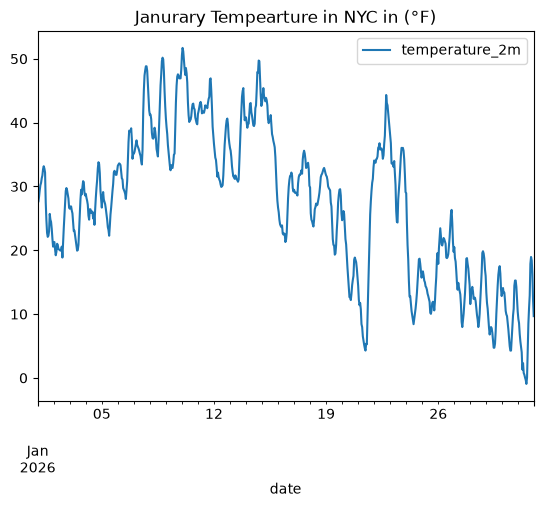

In [11]:
hourly_dataframe.plot(x='date', y=['temperature_2m'], kind='line', title='Janurary Tempearture in NYC in (°F)')
plt.show()

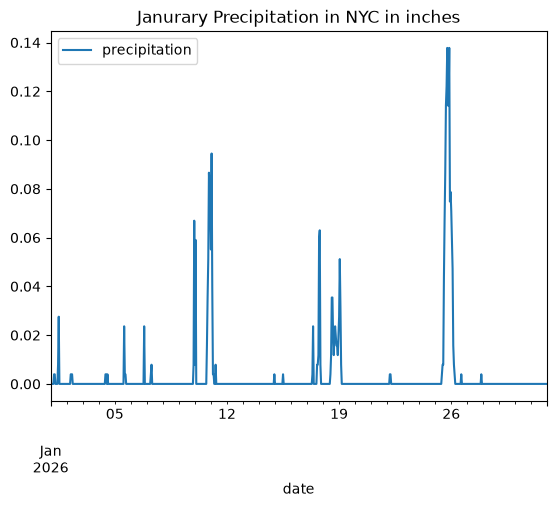

In [18]:
hourly_dataframe.plot(x='date', y=['precipitation'], kind='line', title='Janurary Precipitation in NYC in inches')
plt.show()

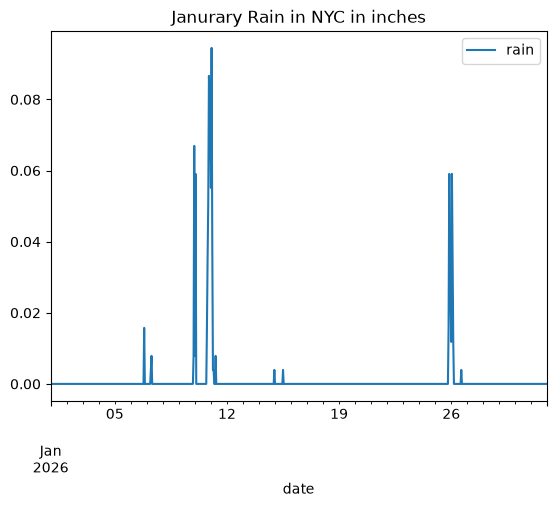

In [27]:
hourly_dataframe.plot(x='date', y=['rain'], kind='line', title='Janurary Rain in NYC in inches')
plt.show()

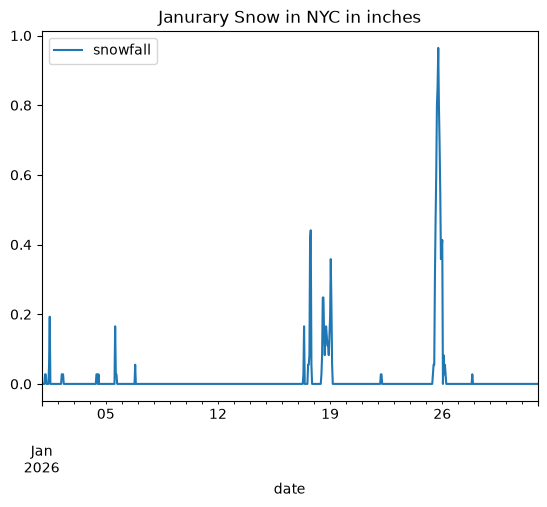

In [28]:
hourly_dataframe.plot(x='date', y=['snowfall'], kind='line', title='Janurary Snow in NYC in inches')
plt.show()

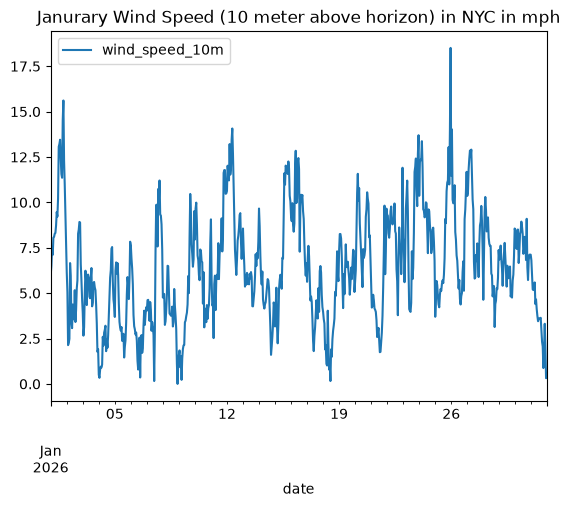

In [29]:
hourly_dataframe.plot(x='date', y=['wind_speed_10m'], kind='line', title='Janurary Wind Speed (10 meter above horizon) in NYC in mph')
plt.show()